# A21 两个团队为什么都挤在黄金时段？

两个团队各选黄金或普通时段。评分体现曝光与拥挤的假设取舍。找出最佳回应、纳什均衡与总收益最优组合，并检验“均衡就是最好”是否成立。

先修：已完成 AI 基础课；会使用列表、字典、函数和 NumPy。涉及的新结构在本例分步解释。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 收益矩阵必须解释每个格子
A[i,j]是行团队选i、列团队选j时行团队的收益；B[i,j]是同一局面的列团队收益。分数为教学假设，不能视为真实团队偏好的测量。

In [2]:
import json
import itertools
import math
import numpy as np
import pandas as pd

def save_results(metrics, recommendation):
    """只负责保存实际计算结果；决策逻辑在下文。"""
    def convert(value):
        return value.item() if hasattr(value, "item") else str(value)
    (OUT_DIR / "metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2, default=convert), encoding="utf-8")
    (OUT_DIR / "决策建议.md").write_text(
        "# 本次运行的决策建议\n\n" + recommendation +
        "\n\n数据为本例明确给定的教学场景；结论仅对模型、目标与已检查条件成立。\n",
        encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2, default=convert))
    print(recommendation)

import nashpy as nash
labels=["黄金","普通"]
A=np.array([[2.,4.],[1.,3.]])
B=np.array([[2.,1.],[4.,3.]])
records=[dict(team1=labels[i],team2=labels[j],payoff1=A[i,j],payoff2=B[i,j]) for i in range(2) for j in range(2)]
pd.DataFrame(records).to_csv(DATA_DIR/"收益矩阵.csv",index=False,encoding="utf-8-sig")
def pure_equilibria(pay_a,pay_b):
    return [(i,j) for i in range(pay_a.shape[0]) for j in range(pay_a.shape[1])
            if pay_a[i,j]>=pay_a[:,j].max()-1e-9 and pay_b[i,j]>=pay_b[i,:].max()-1e-9]


## 2. 单方改变能否获利？
纳什均衡只要求在别人不变时，任何一方都没有更好的单方选择。不要求社会总收益最大。逐格计算最佳回应比背术语更容易核对。

In [3]:
pure=pure_equilibria(A,B)
assert pure==[(0,0)]
total=A+B;social=tuple(int(x) for x in np.unravel_index(np.argmax(total),total.shape))
assert social==(1,1)
best_responses={"team1_to_gold":int(np.argmax(A[:,0])),"team1_to_normal":int(np.argmax(A[:,1])),
                "team2_to_gold":int(np.argmax(B[0,:])),"team2_to_normal":int(np.argmax(B[1,:]))}
print("均衡",pure,"总收益更高的组合",social,"最佳回应",best_responses)


均衡 [(0, 0)] 总收益更高的组合 (1, 1) 最佳回应 {'team1_to_gold': 0, 'team1_to_normal': 0, 'team2_to_gold': 0, 'team2_to_normal': 0}


## 3. 用Nashpy求混合策略并独立检查
概率向量x、y分别描述两队选择。`x @ A @ y`是期望收益；独立检查所有纯动作的期望收益不高于当前混合收益，从而检查没有单方获利偏离。

In [4]:
def check_equilibrium(pay_a,pay_b,x,y,tol=1e-7):
    x=np.asarray(x);y=np.asarray(y)
    if np.any(x < -tol) or np.any(y < -tol) or not np.isclose(x.sum(),1) or not np.isclose(y.sum(),1):return False
    u=float(x@pay_a@y);v=float(x@pay_b@y)
    return np.max(pay_a@y)<=u+tol and np.max(x@pay_b)<=v+tol
equilibria=list(nash.Game(A,B).support_enumeration())
assert equilibria and all(check_equilibrium(A,B,x,y) for x,y in equilibria)
assert not check_equilibrium(A,B,np.array([0.,1.]),np.array([0.,1.]))
# 拥挤收费是规则改变，支付是否算社会损失需单独定义。
fee=1.5; adjusted_a=A.copy();adjusted_b=B.copy()
adjusted_a[0,:]-=fee;adjusted_b[:,0]-=fee
after=pure_equilibria(adjusted_a,adjusted_b)
assert after==[(1,1)]


## 4. 推荐协调规则而不冒充行为预测
矩阵假设给定后，均衡分析可以解释激励。若加入黄金时段费用会改变均衡，应说明费用由谁收取、能否转移，而不能直接说总收益凭空增加。

In [5]:
plt.imshow(total,cmap="YlGnBu");plt.xticks(range(2),labels);plt.yticks(range(2),labels)
for i in range(2):
    for j in range(2):plt.text(j,i,f"({A[i,j]:g},{B[i,j]:g})",ha="center",va="center")
plt.xlabel("团队2");plt.ylabel("团队1");plt.title("收益矩阵；底色为两队收益之和")
plt.tight_layout();plt.savefig(OUT_DIR/"收益与均衡.png");plt.close()
save_results({"pure_equilibria":pure,"social_optimum":social,"equilibrium_total":float(total[pure[0]]),
              "social_total":float(total[social]),"fee":fee,"equilibria_after_fee":after},
             f"当前唯一纯策略均衡为双方选择黄金，总收益{total[0,0]:g}；双方普通的总收益为{total[1,1]:g}。"
             f"在本收益假设下，每方黄金费用{fee}使普通组合成为均衡；这只是规则敏感性实验，需要确认真实偏好与费用归属。")


{
  "pure_equilibria": [
    [
      0,
      0
    ]
  ],
  "social_optimum": [
    1,
    1
  ],
  "equilibrium_total": 4.0,
  "social_total": 6.0,
  "fee": 1.5,
  "equilibria_after_fee": [
    [
      1,
      1
    ]
  ]
}
当前唯一纯策略均衡为双方选择黄金，总收益4；双方普通的总收益为6。在本收益假设下，每方黄金费用1.5使普通组合成为均衡；这只是规则敏感性实验，需要确认真实偏好与费用归属。


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

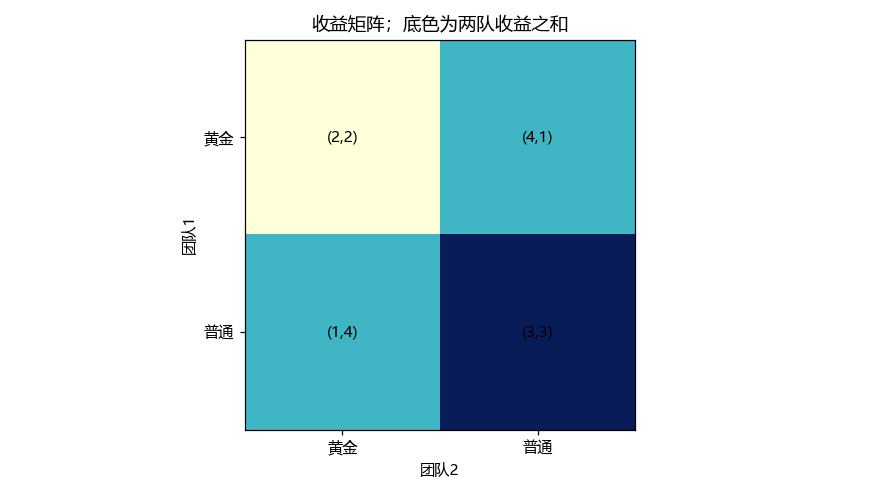

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
完全信息、同时选择、收益可量化是本例假设。均衡不是必然发生的心理预测；总收益更高也不自动代表公平。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。